In [1]:
from utils.evaluation_utils import *
from utils.metrics_utils import *
from IPython.display import display

## Beispiel-Bild
- Regensburg DEZ-Kreuzung
- von Mapillary
- selbst annotiert

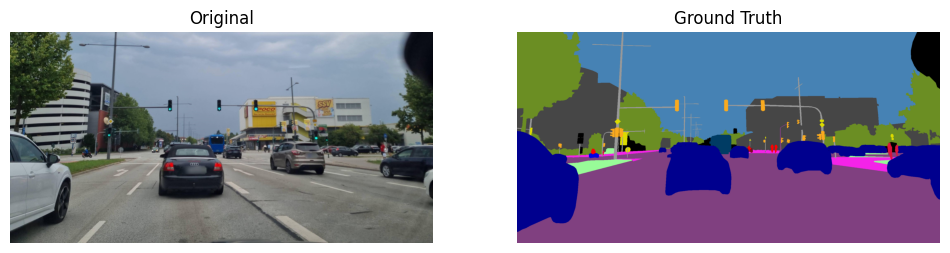

In [2]:
cvat_ctx = load_demo_context(image_name="bild6r.jpg", label_name="bild6.png")
image = cvat_ctx["image"]
rgb_label = cvat_ctx["label"]

plot_images(image, "Original", rgb_label, "Ground Truth")

classes = cvat_ctx["classes"]
color_to_class = cvat_ctx["color_to_class"]
image_key = cvat_ctx["image_key"]

def show_instance_metrics(rgb_mask, picture_name=None):
    manual_key = picture_name or image_key
    report = make_instance_report(
        rgb_mask,
        image_key,
        classes,
        color_to_class,
        manual_metrics=MANUAL_METRICS,
        instance_methods=INSTANCE_METHODS,
        manual_key=manual_key,
    )
    print("Summary: ")
    display(report["summary"])
    print("Instances (computed + ground truth):")
    display(report["instances"])
    plot_instance_comparison(
        report["instance_comparison"],
        title=f"Instance Comparison: {image_key}",
    )
    return float(report["summary"].iloc[0]["overall_pct_instance_diff"])


## Segmentierung

Loaded model: deeplabv3plus
Best checkpoint:
 - Epoch: 122.000
 - Train Loss: 0.027
 - Train Accuracy: 0.971
 - Train MIoU: 0.810
 - Val Loss: 0.081
 - Val Accuracy: 0.952
 - Val MIoU: 0.634


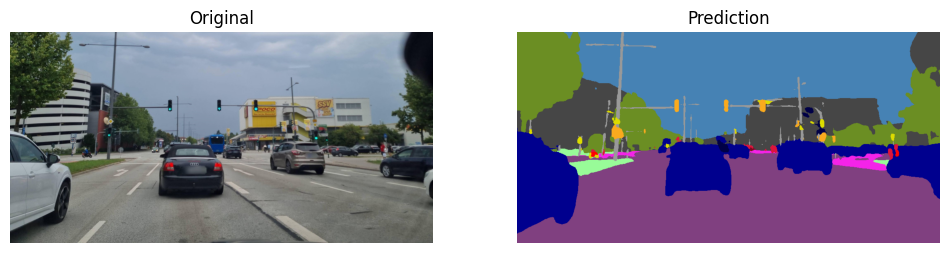

Results:
 - MIoU: 0.47024882558014536
 - Pixel Accuracy: 0.9519867300987244
Summary: 


,width,height,entropy,num_present_classes,overall_pct_instance_diff
image,,,,,
bild6.png,1024,512,1.70313,14,55.62


Instances (computed + ground truth):


,method,computed_instances,ground_truth_instances,diff,pct_diff
class,,,,,
bicycle,cc,1,3,2,67
building,watershed,4,5,1,20
bus,peaks,0,1,1,100
car,peaks,20,16,4,25
guard rail,cc,0,0,0,0
motorcycle,cc,0,1,1,100
parking,cc,0,0,0,0
person,cc,9,3,6,200
pole,watershed,30,15,15,100


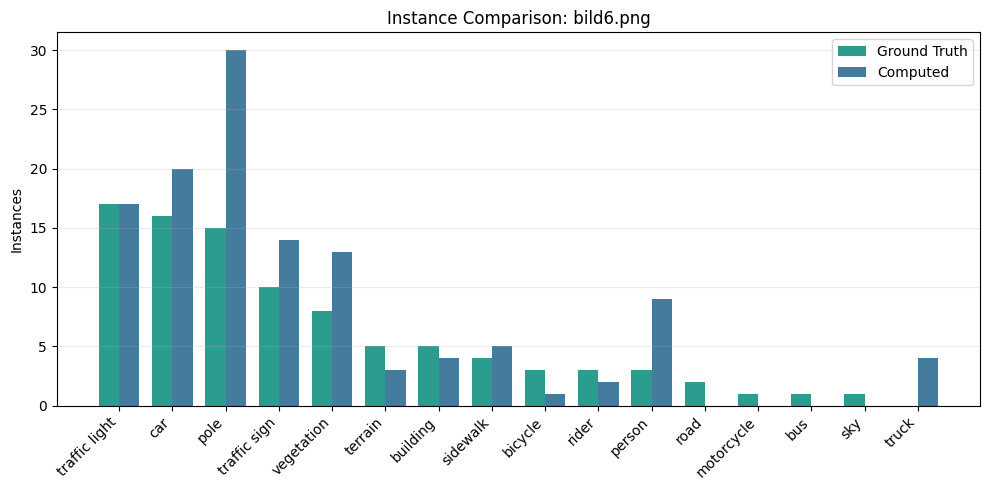

In [3]:
model, device, _ = load_model("deeplab", "deeplab_cityscapes_giga_run_3271161")
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

overall_pct_instance_diff = show_instance_metrics(rgb_pred)


In [4]:
#TODO
model, device, _ = load_model("segformer", "segformer_cityscapes_giga_run_") ###
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

show_instance_metrics(rgb_pred)


FileNotFoundError: [Errno 2] No such file or directory: '../checkpoints/segformer_cityscapes_giga_run_/best_segformer_cityscapes_giga_run_.pth'

In [ ]:
#TODO
model, device, _ = load_model("unet", "unet_cityscapes_giga_run_") ###
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

show_instance_metrics(rgb_pred)
